# 1. Первичное ознакомление с данными

## Загрузка данных

In [4]:
csv= pd.read_csv('Forbes Richest Atheletes (Forbes Richest Athletes 1990-2020).csv')

## Импорт библиотек

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

**Выведем первые 10 строк**

In [5]:
csv.head()

,S.NO,Name,Nationality,Current Rank,Previous Year Rank,Sport,Year,earnings ($ million)
0,1,Mike Tyson,USA,1,NaN,boxing,1990,28.6
1,2,Buster Douglas,USA,2,NaN,boxing,1990,26.0
2,3,Sugar Ray Leonard,USA,3,NaN,boxing,1990,13.0
3,4,Ayrton Senna,Brazil,4,NaN,auto racing,1990,10.0
4,5,Alain Prost,France,5,NaN,auto racing,1990,9.0


**Определяем размер датасета**

In [6]:
csv.shape

(301, 8)

**Проверяем типы данных**

In [7]:
csv.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   S.NO                  301 non-null    int64  
 1   Name                  301 non-null    str    
 2   Nationality           301 non-null    str    
 3   Current Rank          301 non-null    int64  
 4   Previous Year Rank    277 non-null    str    
 5   Sport                 301 non-null    str    
 6   Year                  301 non-null    int64  
 7   earnings ($ million)  301 non-null    float64
dtypes: float64(1), int64(3), str(4)
memory usage: 18.9 KB


**Проверяем есть ли дубликаты**

In [8]:
duplicates = csv.duplicated().sum()

In [9]:
print("Количество дубликатов:", duplicates)

Количество дубликатов: 0


**Дубликаты отсутствуют соответственно их доля 0%**

<span style="color: darkviolet;">**Описание датасета:**</span>   
Датасет содержит сведения о самых высокооплачиваемых спортсменах по версии Forbes за 1990–2020 годы.  
*Наблюдение (строка)* — спортсмен, включённый в рейтинг Forbes в определённом году.  
<span style="color: darkviolet;">**Описание признаков:**</span>  
- **S.NO** — порядковый номер записи в датасете.
- **Name** — имя и фамилия спортсмена.
- **Nationality** — гражданство или страна, которую представляет спортсмен.
- **Current Rank** — позиция спортсмена в рейтинге самых высокооплачиваемых спортсменов за указанный год. 
- **Previous Year Rank** — позиция спортсмена в рейтинге за предыдущий год.
- **Sport** — вид спорта, которым занимается спортсмен.
- **Year** — год публикации рейтинга Forbes.
- **earnings ($ million)** — годовой доход спортсмена в миллионах долларов США по оценке Forbes.


# 2. Разведочный анализ данных (EDA)

## 2.1 Числовые признаки

**Считаем долю пропущенных значений**

In [11]:
# .isna() - Проверяет каждую ячейку на пропуск: True — значение пропущено, False — значение есть.
# .isna().mean() - Считает среднее значение по каждому столбцу.
csv.select_dtypes(include="number").isna().mean() * 100

S.NO                    0.0
Current Rank            0.0
Year                    0.0
earnings ($ million)    0.0
dtype: float64

**В числовых столбцах датасета нет пропущенных значений, соответвенно доля пропущенных значение = 0 %**

**считаем минимум и максимум**

In [14]:
# минимум
csv.select_dtypes(include="number").min()  

S.NO                       1.0
Current Rank               1.0
Year                    1990.0
earnings ($ million)       8.1
dtype: float64

In [15]:
# максимум
csv.select_dtypes(include="number").max() 

S.NO                     301.0
Current Rank              10.0
Year                    2020.0
earnings ($ million)     300.0
dtype: float64

**считаем среднее и медиану**

In [16]:
# среднее  
csv.select_dtypes(include="number").mean()

S.NO                     151.000000
Current Rank               5.448505
Year                    2005.122924
earnings ($ million)      45.516279
dtype: float64

In [17]:
# медиана  
csv.select_dtypes(include="number").median()

S.NO                     151.0
Current Rank               5.0
Year                    2005.0
earnings ($ million)      39.0
dtype: float64

**дисперсию**

In [18]:
# дисперсия  
csv.select_dtypes(include="number").var(ddof=0)

S.NO                    7550.000000
Current Rank               8.101169
Year                      81.875255
earnings ($ million)    1120.214187
dtype: float64

**квантиль**

In [20]:
# квантиль 0.1  
csv.select_dtypes(include="number").quantile([0.1])

,S.NO,Current Rank,Year,earnings ($ million)
0.1,31.0,2.0,1993.0,13.5


In [21]:
# квантиль 0.9  
csv.select_dtypes(include="number").quantile([0.9])

,S.NO,Current Rank,Year,earnings ($ million)
0.9,271.0,9.0,2017.0,85.5


**первый и третий квартиль**

In [23]:
csv.select_dtypes(include="number").quantile([0.25, 0.75])

,S.NO,Current Rank,Year,earnings ($ million)
0.25,76.0,3.0,1997.0,24.0
0.75,226.0,8.0,2013.0,59.4


**Дополнительно:**

In [26]:
csv.describe()

,S.NO,Current Rank,Year,earnings ($ million)
count,301.000000,301.000000,301.000000,301.000000
mean,151.000000,5.448505,2005.122924,45.516279
std,87.035433,2.850995,9.063563,33.525337
min,1.000000,1.000000,1990.000000,8.100000
25%,76.000000,3.000000,1997.000000,24.000000
50%,151.000000,5.000000,2005.000000,39.000000
75%,226.000000,8.000000,2013.000000,59.400000
max,301.000000,10.000000,2020.000000,300.000000


Видим, что у нас есть высокие значения в столбце earnings ($ million) то есть доход спортсменов

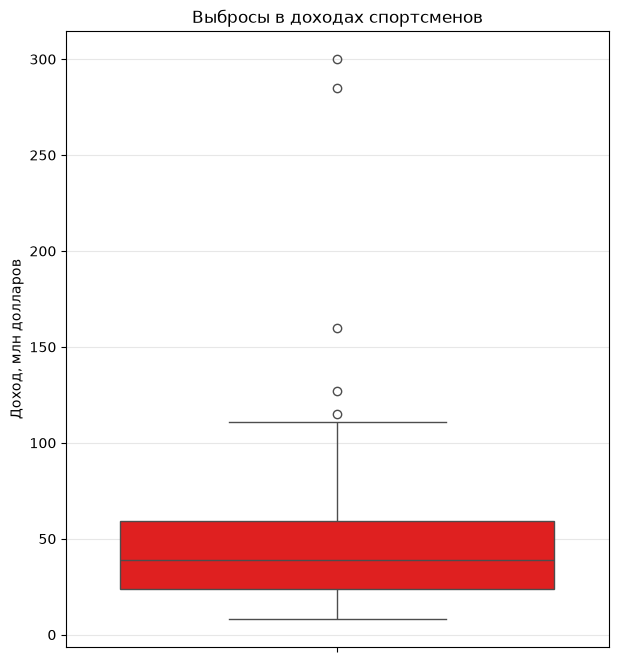

In [32]:
plt.figure(figsize=(7, 8))
sb.boxplot(y=csv['earnings ($ million)'], color='red')
plt.title("Выбросы в доходах спортсменов")
plt.ylabel("Доход, млн долларов")
plt.grid(axis="y", alpha=0.3)
plt.show()


Благодаря графику видно, что у нас есть несколько выбросов выше верхней границы усов 

Построим гистограмму и KDE для наглядности:  

**Гистограмма:**  

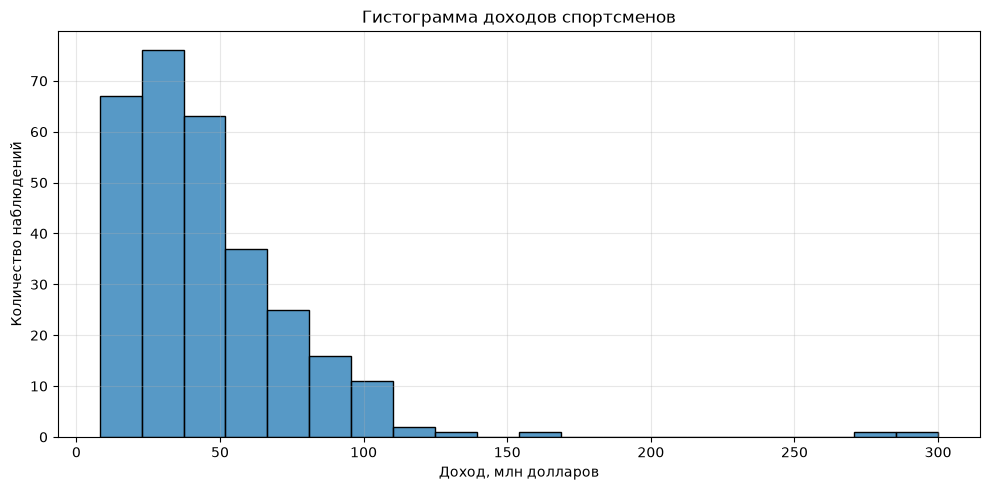

In [40]:
plt.figure(figsize=(10, 5))

sb.histplot(
    data=csv,
    x="earnings ($ million)",
    bins=20,
    kde=False
)

plt.title("Гистограмма доходов спортсменов")
plt.xlabel("Доход, млн долларов")
plt.ylabel("Количество наблюдений")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**KDE:**

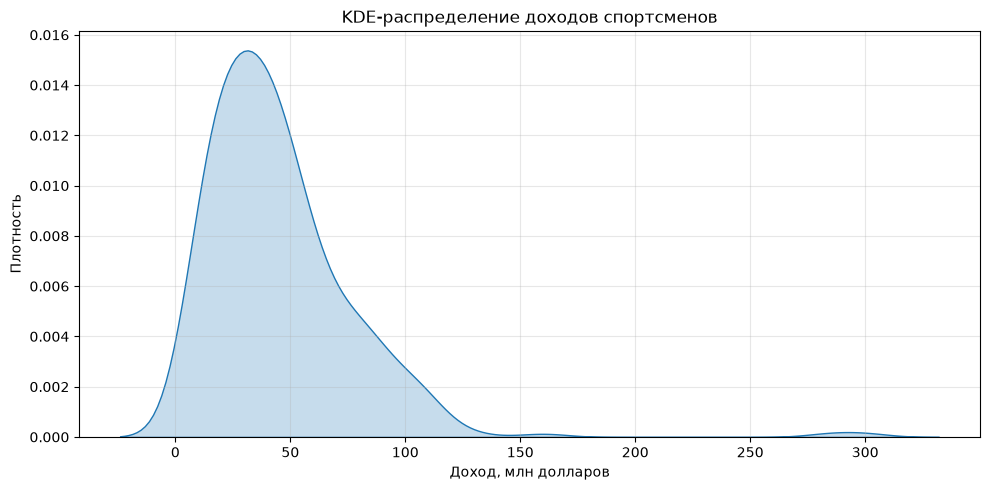

In [41]:
plt.figure(figsize=(10, 5))

sb.kdeplot(
    data=csv,
    x="earnings ($ million)",
    fill=True
)

plt.title("KDE-распределение доходов спортсменов")
plt.xlabel("Доход, млн долларов")
plt.ylabel("Плотность")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Признак earnings ($ million) имеет выраженный правый перекос и длинный правый хвост.

## 2.2 Категориальные признаки

**Считаем долю пропущенных значений**

In [42]:
csv.select_dtypes(include="str").isna().mean() * 100

Name                  0.000000
Nationality           0.000000
Previous Year Rank    7.973422
Sport                 0.000000
dtype: float64

Признак Previous Year Rank  (позиция спортсмена в рейтинге имеет около 8% пропусков)

**Количество уникальных значений**

In [44]:
csv.select_dtypes(include="str").nunique()

Name                  82
Nationality           22
Previous Year Rank    36
Sport                 29
dtype: int64

**Наиболее часто встречающееся значение (моду)**

In [47]:
csv.select_dtypes(include="str").mode()

,Name,Nationality,Previous Year Rank,Sport
0,Michael Jordan,USA,>10,Basketball
1,Tiger Woods,NaN,NaN,NaN


**Дополнительно:**

**Признаки с высокой кардинальностью (много уникальных значений)**

In [54]:
# dropna=True означает: не учитывать пропущенные значения (NaN) при подсчёте уникальных значений.
# sort_values(ascending=False)- сортирует полученные значения по убыванию для удобства просмотра

csv.select_dtypes(include="str").nunique(dropna=True).sort_values(ascending=False)

Name                  82
Previous Year Rank    36
Sport                 29
Nationality           22
dtype: int64

**Потенциально «шумные» категории (редкие значения)**

In [59]:
for column in csv.select_dtypes(include="str").columns:
    counts = csv[column].value_counts().sort_values().head(5)

    print(f"\nСтолбец: {column}")
    print(counts.to_string(header=False))


Столбец: Name
Cecil Fielder     1
Gerhard Berger    1
Michael Moorer    1
Deion Sanders     1
Emmit Smith       1

Столбец: Nationality
Australia           1
Austria             1
Russia              1
Dominican           1
Northern Ireland    1

Столбец: Previous Year Rank
40     1
22     1
38     1
26     1
>14    1

Столбец: Sport
MMA                             1
American Football / Baseball    1
Hockey                          1
cycling                         1
NBA                             1


**Краткие выводы:**

**Name**
Пропущенные значения отсутствуют. В столбце содержится 82 уникальных имени, поэтому он обладает самой высокой кардинальностью.  
Редкие имена, встречающиеся один раз, нельзя автоматически считать шумом ,поскольку для имён единичная частота естественна. Возможно по данному столбцу нужно привести к единому формату регистр и проверить на опечатки 

**Nationality**  
Пропущенные значения отсутствуют. 22 уникальные категории.  
Редкие значения Australia, Austria, Russia и Northern Ireland не обязательно являются шумом, поскольку спортсмен с определенной национальностью мог попасть в рейтинг один раз. Возможно проверить значения на разное написание например Dominican Republic встречается часто, а Dominican один раз, но фактически это одно и то же.

**Previous Year Rank**  
Самый неоднозначный столбец. Сразу, что бросается в глаза это то, что столбец имеет строковый тип данных, когда по логике логичнее было бы если бы он имел числовой тип данных. Попапаются таки значения как > 30, что означает, что позиция в рейтинге > 30 места. Но по каким-то причинам точная позиция не указывается, возможно по этой причине признак имеет строковый тип данных. В признаке неоднородный формат, который по-хорому привести к однородному чтобы не было точных и интервальных значений однговременно. Пропуски можно заменить категорией "Нет данных" и в дальнейшем закодировать

**Sport**  
Пропущенные значения отсутствуют, 29 уникальных категорий. Значения MMA и Hockey допустимо редкие аналогично национальности спортсмена. Спортсмены с видами спорта MMA и Hockey могли появиться в рейтинге по одному разу. Однако cycling с маленькой буквы и возможно нужно привести к единому регистру. NBA например это не вид спорта, а спортивная лига. Так же вызывает непонимание  American Football / Baseball  будто 2 вида спорта записаны одной строкой и нужно разделение.

## 3.Визуальный анализ данных

Для числовых признаков ранее была построена диаграмма ящик с усами(boxplot) для определения медианы, разброса и потенциальных выбросов. Доходы выше верхнего уса примерно более 110 млн долларов отображаются как выбросы, возможно это реальные выбросы или высокие зарплаты спортсменов. 

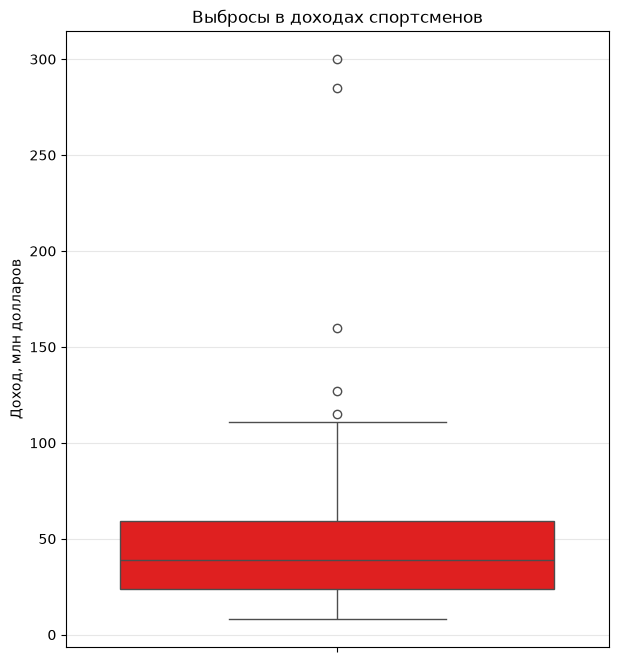

In [64]:
plt.figure(figsize=(7, 8))
sb.boxplot(y=csv['earnings ($ million)'], color='red')
plt.title("Выбросы в доходах спортсменов")
plt.ylabel("Доход, млн долларов")
plt.grid(axis="y", alpha=0.3)
plt.show()

У признака earnings ($ million) годовой доход спортсмена в миллионах долларов США по оценке Forbes. Имеет правый перекос и длинный правый хвост, что можем видеть на гистрограмме и KDE. Гистограмма использовалась для изучения распределения доходов спортсменов

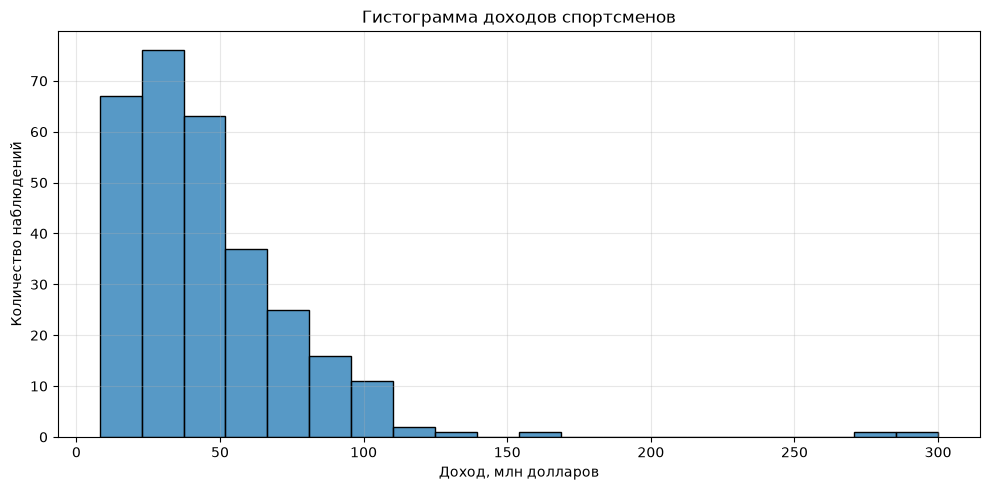

In [65]:
plt.figure(figsize=(10, 5))

sb.histplot(
    data=csv,
    x="earnings ($ million)",
    bins=20,
    kde=False
)

plt.title("Гистограмма доходов спортсменов")
plt.xlabel("Доход, млн долларов")
plt.ylabel("Количество наблюдений")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

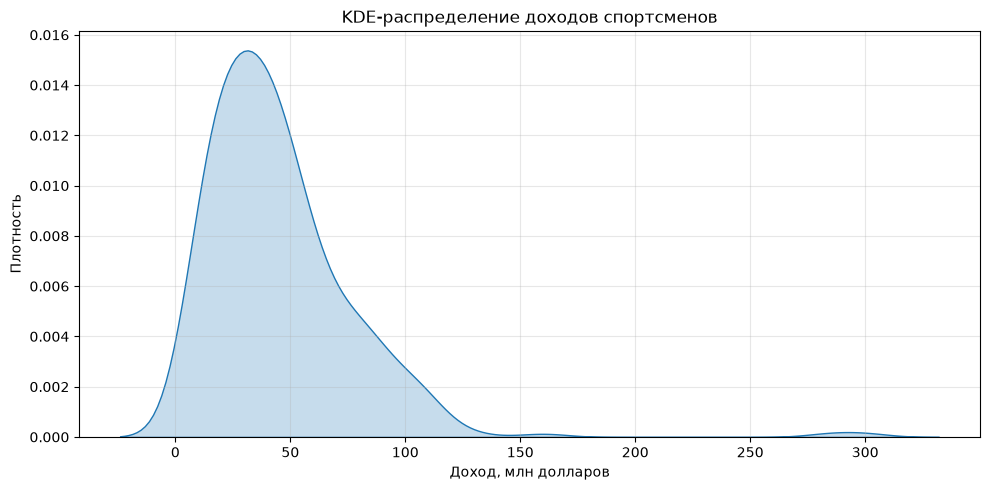

In [66]:
plt.figure(figsize=(10, 5))

sb.kdeplot(
    data=csv,
    x="earnings ($ million)",
    fill=True
)

plt.title("KDE-распределение доходов спортсменов")
plt.xlabel("Доход, млн долларов")
plt.ylabel("Плотность")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Так как наш датасет- это рейтинг высокооплачиваемых спортсменов скорее правый перекос можно считать статистическим выбросом, а не ошибку в данных. У спортсмена вполне мог быть такой высокий доход 

In [70]:
csv.loc[
    csv["earnings ($ million)"].idxmax(),
    ["Name", "Year", "Current Rank", "Sport", "earnings ($ million)"]
]

Name                    Floyd Mayweather
Year                                2015
Current Rank                           1
Sport                             Boxing
earnings ($ million)               300.0
Name: 241, dtype: object

Если посмотреть на спортсмена с самым высоким доходом данные выглядят корректно. 

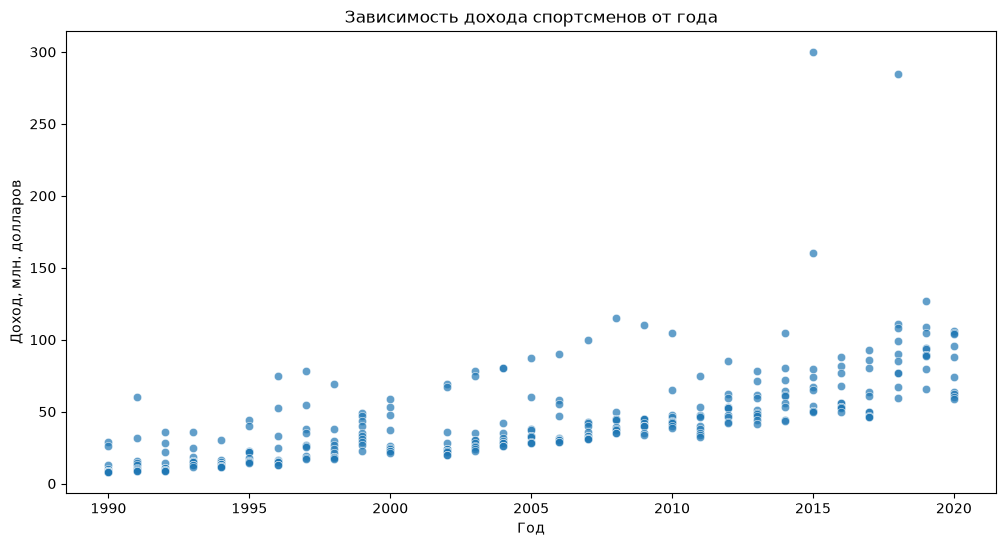

In [73]:
plt.figure(figsize=(12, 6))

sb.scatterplot(
    data=csv,
    x="Year",
    y="earnings ($ million)",
    alpha=0.7
)

plt.title("Зависимость дохода спортсменов от года")
plt.xlabel("Год")
plt.ylabel("Доход, млн. долларов")
plt.show()

Благодаря scatterplot можно увидеть, что самый высокий доход был зафиксирован в 2015 году и составил 300 млн. долларов. 

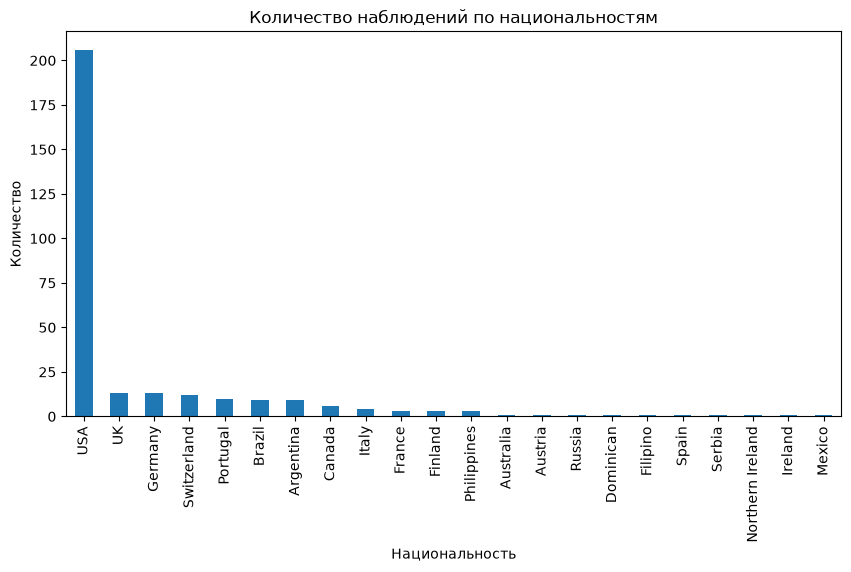

In [78]:
csv["Nationality"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    title="Количество наблюдений по национальностям"
)

plt.xlabel("Национальность")
plt.ylabel("Количество")
plt.show()

С помощью столбчатой диаграммы можем видеть какой национальности спортсменов больше всего в рейтинге